In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 100)

In [2]:
df = pd.read_csv("../data/customer_reviews_india.csv", parse_dates=["Order Date", "Review Date"])
print("Shape:", df.shape)
df.head()

Shape: (7025, 15)


,Review ID,Order ID,Customer ID,Customer Name,Product ID,Product Name,Category,Sub-Category,City,Region,Order Date,Review Date,Rating,Review Title,Review Text
0,RV-100001,IN-2022-100007,AD-10450,Aditya Desai,OFF-FA-10007881,Kangaro Fastener Model 863,Office Supplies,Fasteners,Chennai,South,2022-01-01,2022-01-04,4,Superb,Very nice
1,RV-100002,IN-2022-100040,KG-14875,Kavya Gupta,OFF-ST-10010212,Nilkamal Storage Model 915,Office Supplies,Storage,New Delhi,North,2022-01-02,2022-01-07,5,Very good,"Loved the storage box, my family likes it too!! Installation was easy. Customer service was very..."
2,RV-100003,IN-2022-100029,NS-16810,Nandini Shah,OFF-EN-10007215,Oddy Envelope Model 209,Office Supplies,Envelopes,Chandigarh,North,2022-01-01,2022-01-08,4,Loved it,"Loved the envelopes, my family likes it too."
3,RV-100004,IN-2022-100040,KG-14875,Kavya Gupta,OFF-AP-10004255,Havells Appliance Model 476,Office Supplies,Appliances,New Delhi,North,2022-01-02,2022-01-10,3,Very good,"Loved the appliance, my family likes it too. Packaging was neat and safe. Five stars from me."
4,RV-100005,IN-2022-100079,VM-21415,Vikram Malhotra,OFF-EN-10007104,Navneet Envelope Model 986,Office Supplies,Envelopes,Bengaluru,South,2022-01-03,2022-01-12,3,Not bad,The envelopes is good but a bit expensive.


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7025 entries, 0 to 7024
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Review ID      7025 non-null   str           
 1   Order ID       7025 non-null   str           
 2   Customer ID    7025 non-null   str           
 3   Customer Name  7025 non-null   str           
 4   Product ID     7025 non-null   str           
 5   Product Name   7025 non-null   str           
 6   Category       7025 non-null   str           
 7   Sub-Category   7025 non-null   str           
 8   City           7025 non-null   str           
 9   Region         7025 non-null   str           
 10  Order Date     7025 non-null   datetime64[us]
 11  Review Date    7025 non-null   datetime64[us]
 12  Rating         7025 non-null   int64         
 13  Review Title   7025 non-null   str           
 14  Review Text    6990 non-null   str           
dtypes: datetime64[us](2), int64(1), 

In [4]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

dup = df.drop(columns="Review ID").duplicated().sum()
print("\nDuplicate reviews:", dup)

Missing values:
Review Text    35
dtype: int64

Duplicate reviews: 25


In [5]:
df = df.dropna(subset=["Review Text"])
df = df.drop_duplicates(subset=df.columns.drop("Review ID"))
print("Shape after cleaning:", df.shape)

Shape after cleaning: (6965, 15)


In [6]:
df[["Rating", "Review Title", "Review Text"]].sample(8, random_state=1)

,Rating,Review Title,Review Text
5324,2,Okay,Normal quality labels. Satisfactory overall. Customer care was polite.
1667,5,Loved it,Value for money
1971,5,Great product,the paper looks premium and feels solid. customer service was very helpful. highly recommended. ...
639,4,Loved it,Really good build quality on the storage box!! Smooth experience overall. Packaging was neat and...
2282,3,Average,The storage box is fine for the price.
4851,5,Very good,Very nice
219,3,Very good,Very satisfied with the binder. Good value for money.
5576,5,Superb,Amazing table at this price. Slightly expensive.


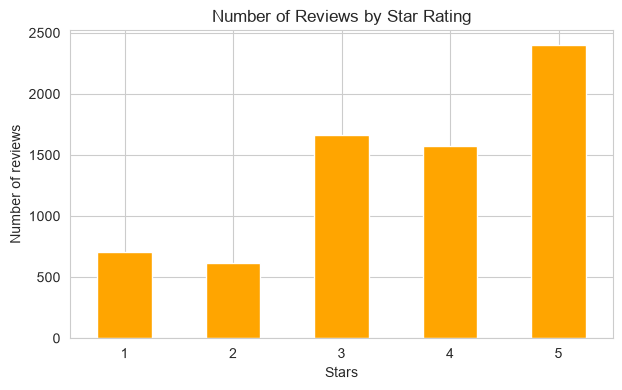

In [7]:
df["Rating"].value_counts().sort_index().plot(kind="bar", color="orange", figsize=(7, 4))
plt.title("Number of Reviews by Star Rating")
plt.xlabel("Stars")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

count    6965.0
mean        9.9
std         5.1
min         1.0
25%         6.0
50%        10.0
75%        13.0
max        30.0
Name: Word Count, dtype: float64


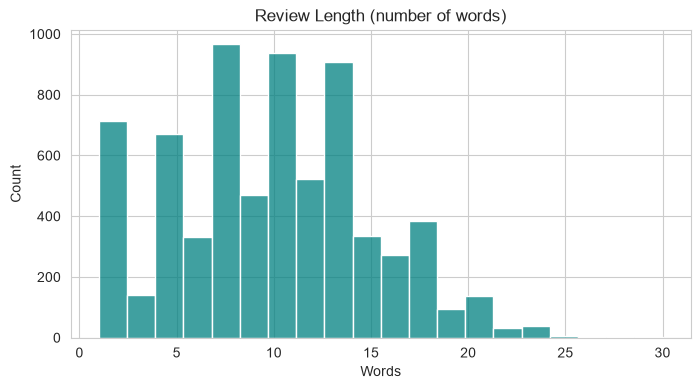

In [8]:
df["Word Count"] = df["Review Text"].str.split().str.len()
print(df["Word Count"].describe().round(1))

plt.figure(figsize=(8, 4))
sns.histplot(df["Word Count"], bins=20, color="teal")
plt.title("Review Length (number of words)")
plt.xlabel("Words")
plt.show()

In [9]:
def rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["Sentiment"] = df["Rating"].apply(rating_to_sentiment)

print(df["Sentiment"].value_counts())
print("\nPercentage:")
print((df["Sentiment"].value_counts(normalize=True) * 100).round(1))

Sentiment
Positive    3977
Neutral     1664
Negative    1324
Name: count, dtype: int64

Percentage:
Sentiment
Positive    57.1
Neutral     23.9
Negative    19.0
Name: proportion, dtype: float64


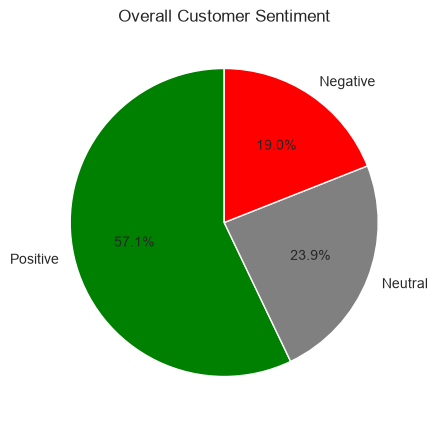

In [10]:
colors = {"Positive": "green", "Neutral": "gray", "Negative": "red"}
counts = df["Sentiment"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%",
        colors=[colors[s] for s in counts.index], startangle=90)
plt.title("Overall Customer Sentiment")
plt.show()

Sentiment
Negative    10.8
Neutral      9.1
Positive     9.9
Name: Word Count, dtype: float64


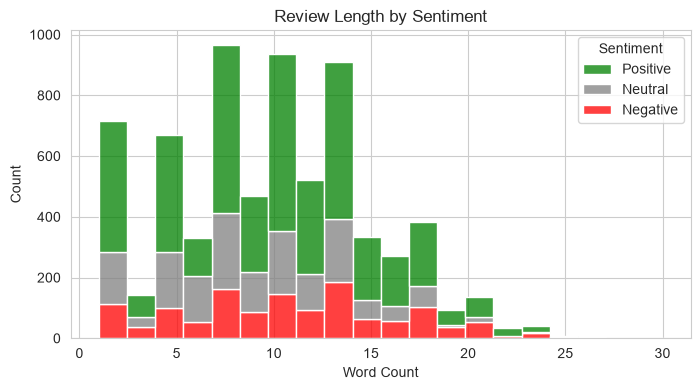

In [11]:
print(df.groupby("Sentiment")["Word Count"].mean().round(1))

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Word Count", hue="Sentiment", bins=20, palette=colors, multiple="stack")
plt.title("Review Length by Sentiment")
plt.show()

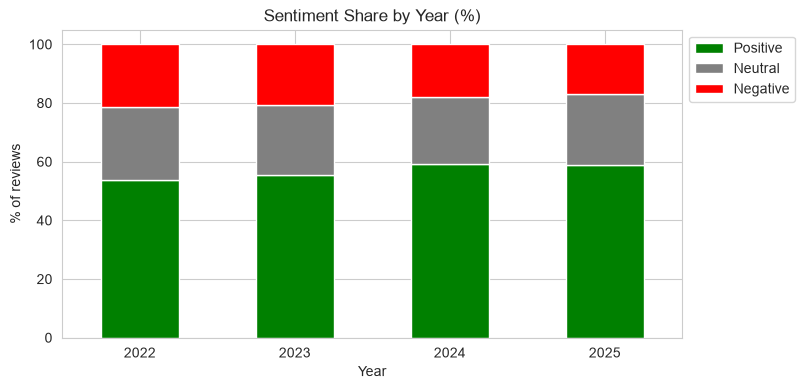

Sentiment  Positive  Neutral  Negative
Year                                  
2022           53.7     25.0      21.4
2023           55.4     23.9      20.8
2024           59.1     22.9      18.0
2025           59.0     24.1      17.0


In [12]:
df["Year"] = df["Review Date"].dt.year
yearly = pd.crosstab(df["Year"], df["Sentiment"], normalize="index") * 100
yearly = yearly[["Positive", "Neutral", "Negative"]]

yearly.plot(kind="bar", stacked=True, color=["green", "gray", "red"], figsize=(8, 4))
plt.title("Sentiment Share by Year (%)")
plt.ylabel("% of reviews")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

print(yearly.round(1))

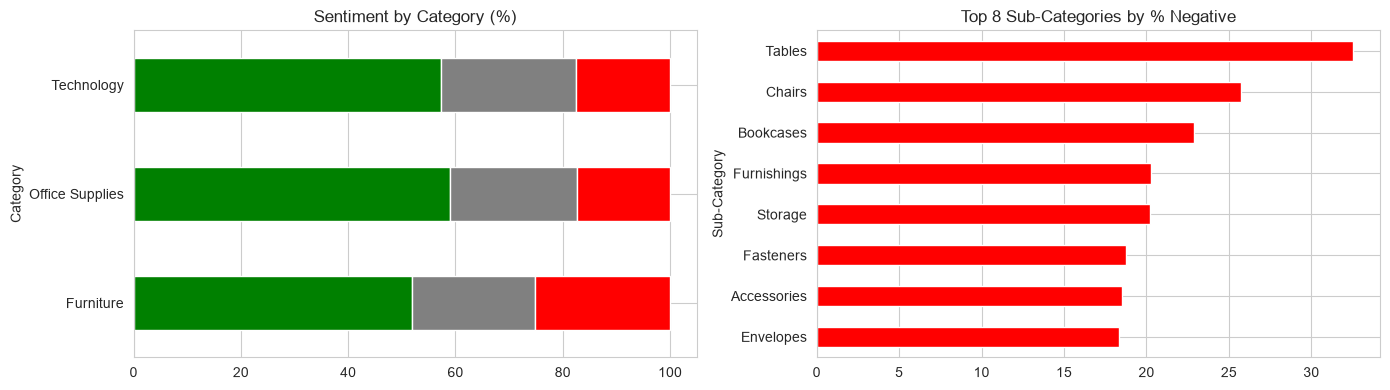

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

(pd.crosstab(df["Category"], df["Sentiment"], normalize="index") * 100)[["Positive", "Neutral", "Negative"]].plot(
    kind="barh", stacked=True, color=["green", "gray", "red"], ax=ax[0], legend=False)
ax[0].set_title("Sentiment by Category (%)")

neg_sub = (df["Sentiment"] == "Negative").groupby(df["Sub-Category"]).mean().sort_values() * 100
neg_sub.tail(8).plot(kind="barh", color="red", ax=ax[1])
ax[1].set_title("Top 8 Sub-Categories by % Negative")

plt.tight_layout()
plt.show()

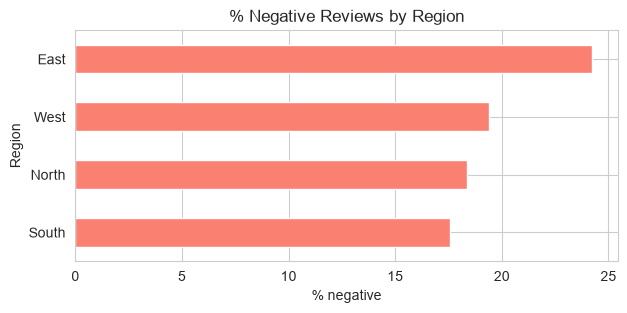

Region
South    17.6
North    18.4
West     19.4
East     24.2
Name: Sentiment, dtype: float64


In [14]:
neg_region = (df["Sentiment"] == "Negative").groupby(df["Region"]).mean().sort_values() * 100
neg_region.plot(kind="barh", color="salmon", figsize=(7, 3))
plt.title("% Negative Reviews by Region")
plt.xlabel("% negative")
plt.show()

print(neg_region.round(1))

In [15]:
df.to_csv("../data/reviews_labeled.csv", index=False)
print("Saved:", df.shape)

Saved: (6965, 18)
